# 00 · Data preparation: from Dryad text files to model input

Every model in the later notebooks reads the same `dataset.npz`. This notebook builds it and documents each decision: which files are usable, where time zero lies, which row is which electrode, and how epochs become 12 × 128 model inputs.

*Data: Gao et al. (2014), public Dryad release, doi:10.5061/dryad.2qc64. Own analysis; the plan (folds, training task, decision rule) was fixed before results.*

In [1]:
import os, json, numpy as np, matplotlib.pyplot as plt
# Point GAO_DIR at the "14 electrodes-30 subjects" folder of the Dryad release; GKT_WORK holds all derived files
os.environ.setdefault("GAO_DIR", "./data/14 electrodes-30 subjects/")
os.environ.setdefault("GKT_WORK", "./work/")
from gkt_utils import *
print("data:", GAO_DIR, "| work:", WORK)

data: ./data/14 electrodes-30 subjects/ | work: ./work/


## 1. Channel order from the raw recording
The released text files store 14 rows per epoch without labels. The release also contains one raw Neuroscan recording, `lying/subject12/session4/xiaowushuang1.cnt`. Its header lists the channel labels in storage order. The same order is assumed for every exported file (only one raw file is available).

In [2]:
import struct
cnt = os.path.join(GAO_DIR, "lying/subject12/session4/xiaowushuang1.cnt")
b = open(cnt, "rb").read()
n_ch = struct.unpack("<H", b[370:372])[0]; fs = struct.unpack("<H", b[376:378])[0]
labels = [b[900 + 75 * i: 900 + 75 * i + 10].split(b"\0")[0].decode() for i in range(n_ch)]
print(n_ch, "channels at", fs, "Hz:", labels)
assert [l.upper() for l in labels] == [c.upper() for c in CHANNELS]

14 channels at 500 Hz: ['OZ', 'PZ', 'P4', 'C4', 'P3', 'CZ', 'C3', 'FZ', 'F4', 'F3', 'FP2', 'FP1', 'HEOG', 'VEOG']


## 2. File audit and caching
Each stimulus file (`target`, `probe`, `irrelevant` per person and session) is checked:
* empty or malformed → excluded
* not 14 rows or not a multiple of 800 columns → not epoched, excluded
* first 150 samples do not average to zero (no 300-ms baseline) → excluded
* exact duplicates (same MD5) → both copies excluded

Usable epochs are cut to **0–998 ms** (samples 151–650, 500 samples at 500 Hz) and resampled to **128 Hz** (128 samples). The per-epoch maximum absolute EEG amplitude is stored for artifact rejection.

The loop skips files already in `manifest.json`, so it can be re-run; a first full pass over the 568-MB release takes a long time.

In [3]:
import hashlib, glob
from scipy.signal import resample_poly
os.makedirs(P("cache"), exist_ok=True)
man_path = P("manifest.json")
man = json.load(open(man_path)) if os.path.exists(man_path) else {}
files = sorted(f for f in glob.glob(os.path.join(GAO_DIR, "*", "subject*", "session*", "*", "*"))
               if os.path.isfile(f) and not f.endswith(".cnt"))   # two files in the release have no .txt extension
print(len(files), "stimulus files found")
new = 0
for f in files:
    rel = os.path.relpath(f, GAO_DIR).replace("\\", "/")
    g, subj, sess, stim, _ = rel.split("/")
    key = f"{g}/{subj}/{sess}/{stim}"
    if key in man: continue
    raw = open(f, "rb").read(); new += 1
    rec = dict(group=g, subject=int(subj[7:]), session=int(sess[7:]), stim=stim, file=rel, bytes=len(raw), md5=hashlib.md5(raw).hexdigest())
    if len(raw) == 0: rec.update(status="empty"); man[key] = rec; continue
    try: A = np.loadtxt(f, dtype=np.float32)
    except ValueError: rec.update(status="malformed"); man[key] = rec; continue
    rec["rows"], rec["cols"] = int(A.shape[0]), int(A.shape[1])
    if A.shape[0] != 14 or A.shape[1] % N_RAW: rec.update(status="not_epoched"); man[key] = rec; continue
    E = A.reshape(14, -1, N_RAW).transpose(1, 0, 2)
    base = np.abs(E[:, :, :ONSET].mean(2)).max(1)
    rec["n_epochs"] = int(E.shape[0]); rec["baseline_ok_frac"] = float((base < 0.05).mean())
    if rec["baseline_ok_frac"] < 0.9: rec.update(status="no_baseline"); man[key] = rec; continue
    X128 = resample_poly(E[:, :12, ONSET:ONSET + 500].astype(np.float64), 32, 125, axis=2).astype(np.float32)
    np.savez_compressed(P(f"cache/{g}_{subj}_{sess}_{stim}.npz"), X=X128, maxabs=np.abs(E[:, :12]).max((1, 2)))
    rec.update(status="ok"); man[key] = rec
    json.dump(man, open(man_path, "w"))
json.dump(man, open(man_path, "w"))
import collections
print("newly processed:", new, "| status counts:", collections.Counter(r["status"] for r in man.values()))

447 stimulus files found
newly processed: 0 | status counts: Counter({'ok': 442, 'not_epoched': 2, 'no_baseline': 2, 'malformed': 1})


In [4]:
dup = collections.defaultdict(list)
for k, r in man.items(): dup[r["md5"]].append(k)
dups = {k for ks in dup.values() if len(ks) > 1 for k in ks}
excluded = sorted([k for k, r in man.items() if r["status"] != "ok"] + sorted(dups))
print(len(excluded), "excluded files:"); [print("  ", k, man[k]["status"] if man[k]["status"] != "ok" else "duplicate") for k in excluded]
print("epochs in usable files:", sum(r["n_epochs"] for k, r in man.items() if r["status"] == "ok" and k not in dups))

9 excluded files:
   lying/subject14/session1/irrelevant not_epoched
   lying/subject14/session2/probe duplicate
   lying/subject14/session3/target duplicate
   lying/subject15/session1/target malformed
   lying/subject2/session1/irrelevant duplicate
   lying/subject3/session1/irrelevant duplicate
   lying/subject6/session5/target not_epoched
   lying/subject7/session2/probe no_baseline
   lying/subject7/session5/target no_baseline
epochs in usable files: 25711


## 3. Artifact rejection and the final dataset
Epochs with any EEG channel above ±100 µV are rejected. Labels: `group` 1 = lying folder (knowledgeable), 0 = honest folder (control); `pid` = subject + 100 for the lying folder; `stim` 0 irrelevant, 1 probe, 2 target.

In [5]:
Xs, rows = [], []
for k, r in sorted(man.items()):
    if r["status"] != "ok" or k in dups: continue
    z = np.load(P(f"cache/{r['group']}_subject{r['subject']}_session{r['session']}_{r['stim']}.npz"))
    keep = z["maxabs"] <= 100; Xs.append(z["X"][keep])
    rows += [(int(r["group"] == "lying"), r["subject"] + (100 if r["group"] == "lying" else 0), r["session"], STIM_CODE[r["stim"]])] * int(keep.sum())
L = np.array(rows, dtype=np.int16)
np.savez(P("dataset.npz"), X=np.concatenate(Xs).astype(np.float32), group=L[:, 0], pid=L[:, 1], session=L[:, 2], stim=L[:, 3])
X, G, PID, SES, STIM = load_dataset()
PIDS = sorted(set(PID.tolist()))
print(X.shape, "epochs x channels x samples |", len(PIDS), "people |",
      {k: int((STIM == v).sum()) for k, v in STIM_CODE.items()})

(23388, 12, 128) epochs x channels x samples | 30 people | {'irrelevant': 15583, 'probe': 3890, 'target': 3915}


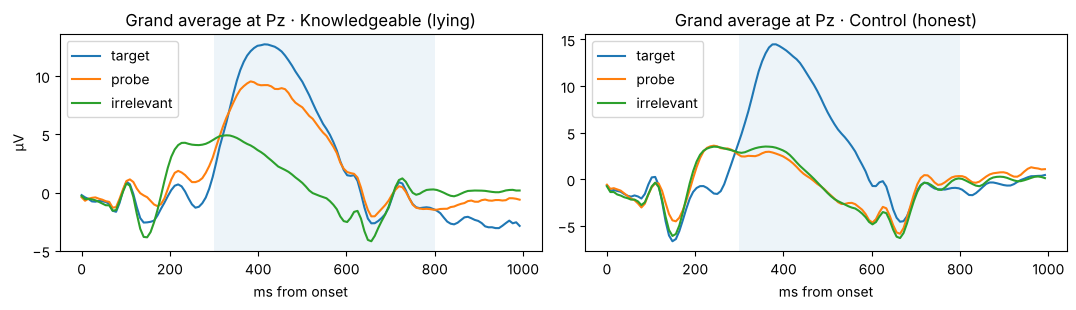

In [6]:
m = (STIM == 2)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for c, lab in ((2, "target"), (1, "probe"), (0, "irrelevant")):
    for gi, g in enumerate((1, 0)):
        ax[gi].plot(TIME_MS, X[(STIM == c) & (G == g), PZ].mean(0), label=lab)
for a, t in zip(ax, ("Knowledgeable (lying)", "Control (honest)")):
    a.set_title(f"Grand average at Pz · {t}"); a.set_xlabel("ms from onset"); a.axvspan(300, 800, alpha=0.08); a.legend()
ax[0].set_ylabel("µV"); plt.tight_layout(); plt.show()

Expected: a large P300 to targets in both groups; a probe P300 resembling the target in the knowledgeable group and resembling the irrelevant items in the control group.